# Atividade Aula 4 — Detecção de objetos com YOLO (Ultralytics) + Roboflow Universe
**Aluno:** Walter Cordeiro Guilhermino · **Prof.:** Francisco Fambrini

Este notebook executa o fluxo completo: prepara o ambiente, baixa o dataset do Roboflow,
inspeciona os dados, treina o YOLO, avalia, testa em imagens novas e **gera automaticamente
o relatório .docx e o .zip de entrega**.

**Como usar:** Runtime → Alterar tipo de runtime → **T4 GPU**. Preencha a célula de configuração
(Passo 0) e rode tudo (Runtime → Executar tudo).

## Passo 0 — Configuração (única célula que você precisa editar)

In [15]:
# ==================== CONFIGURAÇÃO ====================
ALUNO = "Walter Cordeiro Guilhermino"
NOME_ZIP = "AULA4_WalterGuilhermino"

# Link do dataset no Roboflow Universe:
DATASET_URL = "https://universe.roboflow.com/cvproject-soeqs/helmet-detection-swgr3"
DATASET_LICENCA = "CC BY 4.0"

# Opção A: upload do .zip (não usada)
ZIP_PATH = None

# Opção B: download pela API do Roboflow. A chave é pedida na hora e não fica salva.
USAR_API = True
ROBOFLOW_WORKSPACE = "cvproject-soeqs"
ROBOFLOW_PROJETO   = "helmet-detection-swgr3"
ROBOFLOW_VERSAO    = 2

MODELO_BASE = "yolov8n.pt"
EPOCAS = 30                          # mínimo exigido
IMGSZ = 640
BATCH = 16                           # se faltar memória na GPU, use 8
NOME_EXECUCAO = "atividade_aula4"
SALVAR_NO_DRIVE = True               # copia runs/ para o Google Drive

## Passo 1 — Preparar o ambiente

In [16]:
!pip install -q ultralytics roboflow python-docx
import ultralytics
ultralytics.checks()   # confirma versão e GPU disponível

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.4/235.7 GB disk)


## Passo 2/3 — Levar o dataset para o Colab

In [17]:
import os, glob, shutil, zipfile, getpass

DATA_ROOT = "/content/dataset"

if not USAR_API:
    # Opção A — upload do .zip (como no enunciado)
    if ZIP_PATH is None:
        zips = [z for z in glob.glob("/content/*.zip") if not os.path.basename(z).startswith(NOME_ZIP)]
        if not zips:
            from google.colab import files
            print("Nenhum .zip em /content — selecione o arquivo do Roboflow:")
            zips = [os.path.join("/content", n) for n in files.upload()]
        assert len(zips) == 1, f"Encontrei {len(zips)} .zip em /content; defina ZIP_PATH no Passo 0."
        ZIP_PATH = zips[0]
    print("Usando:", ZIP_PATH)
    shutil.rmtree(DATA_ROOT, ignore_errors=True)
    !mkdir -p {DATA_ROOT}
    !unzip -q "{ZIP_PATH}" -d {DATA_ROOT}
else:
    # Opção B — download pela API do Roboflow.
    # A chave é digitada na hora e NÃO fica gravada no notebook entregue.
    from roboflow import Roboflow
    api_key = getpass.getpass("Cole sua API key do Roboflow (não será exibida): ")
    rf = Roboflow(api_key=api_key)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJETO)
    ds = project.version(ROBOFLOW_VERSAO).download("yolov8", location=DATA_ROOT, overwrite=True)
    del api_key

# Alguns zips vêm com uma pasta extra; localiza onde está o data.yaml
yaml_files = glob.glob(f"{DATA_ROOT}/**/data.yaml", recursive=True)
assert yaml_files, "data.yaml não encontrado — confira o download/zip."
DATA_ROOT = os.path.dirname(yaml_files[0])
print("Dataset em:", DATA_ROOT)

Cole sua API key do Roboflow (não será exibida): ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 9754/9754 [00:02<00:00, 3554.19it/s]

Dataset em: /content/dataset


## Passo 4 — Inspecionar o dataset (evidências)

In [18]:
root = DATA_ROOT
print(open(f"{root}/data.yaml").read())   # conteúdo original do data.yaml

contagem = {}
for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    contagem[split] = (len(imgs), len(lbls))
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

TOTAL_IMAGENS = sum(v[0] for v in contagem.values())
print("Total de imagens:", TOTAL_IMAGENS)

names:
- DHelmet
- DNoHelmet
- P1Helmet
- P1NoHelmet
- P2NoHelmet
- motorbike
nc: 6
roboflow:
  license: CC BY 4.0
  project: helmet-detection-swgr3
  url: https://universe.roboflow.com/cvproject-soeqs/helmet-detection-swgr3/dataset/2
  version: 2
  workspace: cvproject-soeqs
test: ../test/images
train: ../train/images
val: ../valid/images

train -> imagens: 3414 | labels: 3414
valid -> imagens: 967 | labels: 967
test -> imagens: 490 | labels: 490
Total de imagens: 4871


## Passo 5 — Conferir e ajustar o data.yaml (caminhos absolutos)

In [19]:
import yaml

with open(f"{root}/data.yaml") as f:
    cfg = yaml.safe_load(f)

# Reescreve com caminhos absolutos (evita o erro de caminho mais comum)
cfg["train"] = f"{root}/train/images"
cfg["val"]   = f"{root}/valid/images"
if os.path.isdir(f"{root}/test/images"):
    cfg["test"] = f"{root}/test/images"
else:
    cfg.pop("test", None)
cfg.pop("path", None)

names = cfg["names"]
if isinstance(names, dict):              # alguns exports usam {0: 'a', 1: 'b'}
    names = [names[k] for k in sorted(names)]
cfg["names"], cfg["nc"] = names, len(names)

with open(f"{root}/data.yaml", "w") as f:
    yaml.safe_dump({k: cfg[k] for k in ["train", "val", "test", "nc", "names"] if k in cfg},
                   f, sort_keys=False, allow_unicode=True, default_flow_style=None, width=1000)

DATA_YAML_TXT = open(f"{root}/data.yaml").read()
print(DATA_YAML_TXT)
for k in ["train", "val", "test"]:
    if k in cfg:
        print(k, "existe?", os.path.isdir(cfg[k]))

assert 2 <= cfg["nc"] <= 15, f"O enunciado pede entre 2 e 15 classes (dataset tem {cfg['nc']})."
assert 300 <= TOTAL_IMAGENS <= 5000, f"O enunciado pede entre 300 e 5.000 imagens (dataset tem {TOTAL_IMAGENS})."

train: /content/dataset/train/images
val: /content/dataset/valid/images
test: /content/dataset/test/images
nc: 6
names: [DHelmet, DNoHelmet, P1Helmet, P1NoHelmet, P2NoHelmet, motorbike]

train existe? True
val existe? True
test existe? True


### Exemplos do treino com as anotações desenhadas
Formato de cada linha do `.txt`: `classe x_centro y_centro largura altura` (normalizados entre 0 e 1).
A célula desenha as caixas convertendo essas coordenadas para pixels.

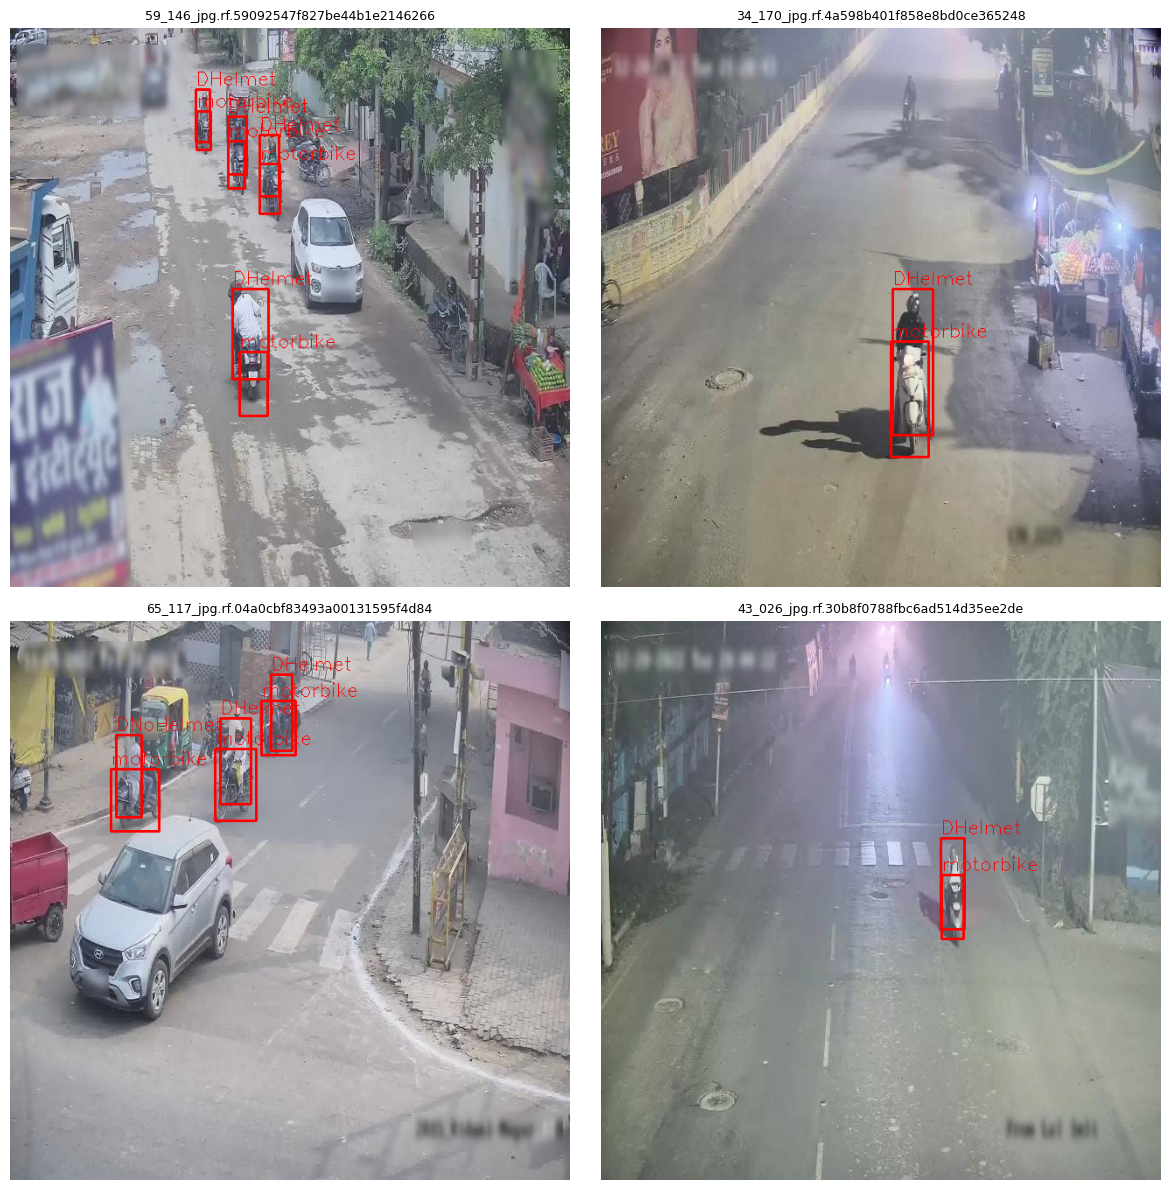

59_146_jpg.rf.59092547f827be44b1e2146266d925ee.txt
5 0.43515625 0.63671875 0.04921875 0.1140625
0 0.42890625 0.5484375 0.0640625 0.16015625
0 0.46328125 0.24765625 0.03515625 0.10859375
5 0.4640625 0.2890625 0.0359375 0.0890625
0 0.40546875 0.21171875 0.0328125 0.10390625
5 0.4046875 0.24609375 0.0296875 0.08515625
5 0.34609375 0.184375 0.025 0.06875
0 0.34453125 0.15859375 0.02421875 0.09296875


In [20]:
import random, cv2, matplotlib.pyplot as plt

EVID = "/content/evidencias"
os.makedirs(EVID, exist_ok=True)
random.seed(42)

def desenhar_anotacoes(img_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = os.path.splitext(img_path.replace("/images/", "/labels/"))[0] + ".txt"
    linhas = open(lbl).read().strip().splitlines() if os.path.exists(lbl) else []
    for ln in linhas:
        p = ln.split()
        if len(p) != 5:          # ignora polígonos (segmentação)
            continue
        c, xc, yc, bw, bh = int(p[0]), *map(float, p[1:])
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), max(2, w // 300))
        cv2.putText(img, names[c], (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, w / 900), (255, 0, 0), max(1, w // 400))
    return img, lbl, linhas

train_imgs = [p for p in glob.glob(f"{root}/train/images/*")
              if os.path.exists(os.path.splitext(p.replace("/images/", "/labels/"))[0] + ".txt")]
amostras = random.sample(train_imgs, 4)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, p in zip(axes.flat, amostras):
    img, lbl, linhas = desenhar_anotacoes(p)
    ax.imshow(img); ax.set_title(os.path.basename(p)[:40], fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{EVID}/amostras_treino.png", dpi=110)
plt.show()

# Conteúdo de um arquivo de label (para mostrar o formato)
_, LABEL_EXEMPLO_PATH, LABEL_EXEMPLO = desenhar_anotacoes(amostras[0])
print(os.path.basename(LABEL_EXEMPLO_PATH))
print("\n".join(LABEL_EXEMPLO))

## Passo 6 — Treinar o modelo

In [21]:
from ultralytics import YOLO

if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive não montou, seguindo sem backup:", e)
        SALVAR_NO_DRIVE = False

model = YOLO(MODELO_BASE)            # pesos pré-treinados (COCO) — transfer learning
results = model.train(
    data=f"{root}/data.yaml",
    epochs=EPOCAS,
    imgsz=IMGSZ,
    batch=BATCH,
    name=NOME_EXECUCAO,
    exist_ok=True,                   # reexecuções sobrescrevem a mesma pasta
    seed=42,
)

RUN_DIR = str(results.save_dir)      # ex.: /content/runs/detect/atividade_aula4
BEST = f"{RUN_DIR}/weights/best.pt"
print("Pasta de saída:", RUN_DIR)

if SALVAR_NO_DRIVE:
    shutil.copytree(RUN_DIR, f"/content/drive/MyDrive/aula4_runs/{NOME_EXECUCAO}", dirs_exist_ok=True)

Drive não montou, seguindo sem backup: Error: credential propagation was unsuccessful
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, 

## Passo 7 — Avaliar o modelo

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2234.9±658.6 MB/s, size: 53.3 KB)
val: Scanning /content/dataset/valid/labels.cache... 967 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 967/967 368.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 4.9it/s 12.6s
                   all        967       4107      0.757      0.706      0.764      0.489
               DHelmet        753       1372      0.868      0.866      0.921      0.602
             DNoHelmet        349        473      0.932      0.784      0.908      0.601
              P1Helmet         10         10       0.94          1      0.995      0.608
            P1NoHelmet        232        302      0.897      0.699      0.829      0.516
            P2NoHelmet          1          1  

,Classe,Precisão,Recall,mAP50,mAP50-95
4,P2NoHelmet,0.000,0.000,0.000,0.000
3,P1NoHelmet,0.897,0.699,0.829,0.516
1,DNoHelmet,0.932,0.784,0.908,0.601
0,DHelmet,0.868,0.866,0.921,0.602
2,P1Helmet,0.940,1.000,0.995,0.608
5,motorbike,0.903,0.887,0.931,0.608


,epoch,train/box_loss,train/cls_loss,val/box_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
25,26,1.1970,0.7212,1.2665,0.7337,0.6926,0.7596,0.4777
26,27,1.1808,0.7085,1.2786,0.7517,0.6987,0.7575,0.4774
27,28,1.1625,0.6919,1.2558,0.7522,0.6800,0.7585,0.4816
28,29,1.1422,0.6825,1.2475,0.7480,0.7120,0.7615,0.4854
29,30,1.1287,0.6679,1.2438,0.7530,0.7086,0.7639,0.4883


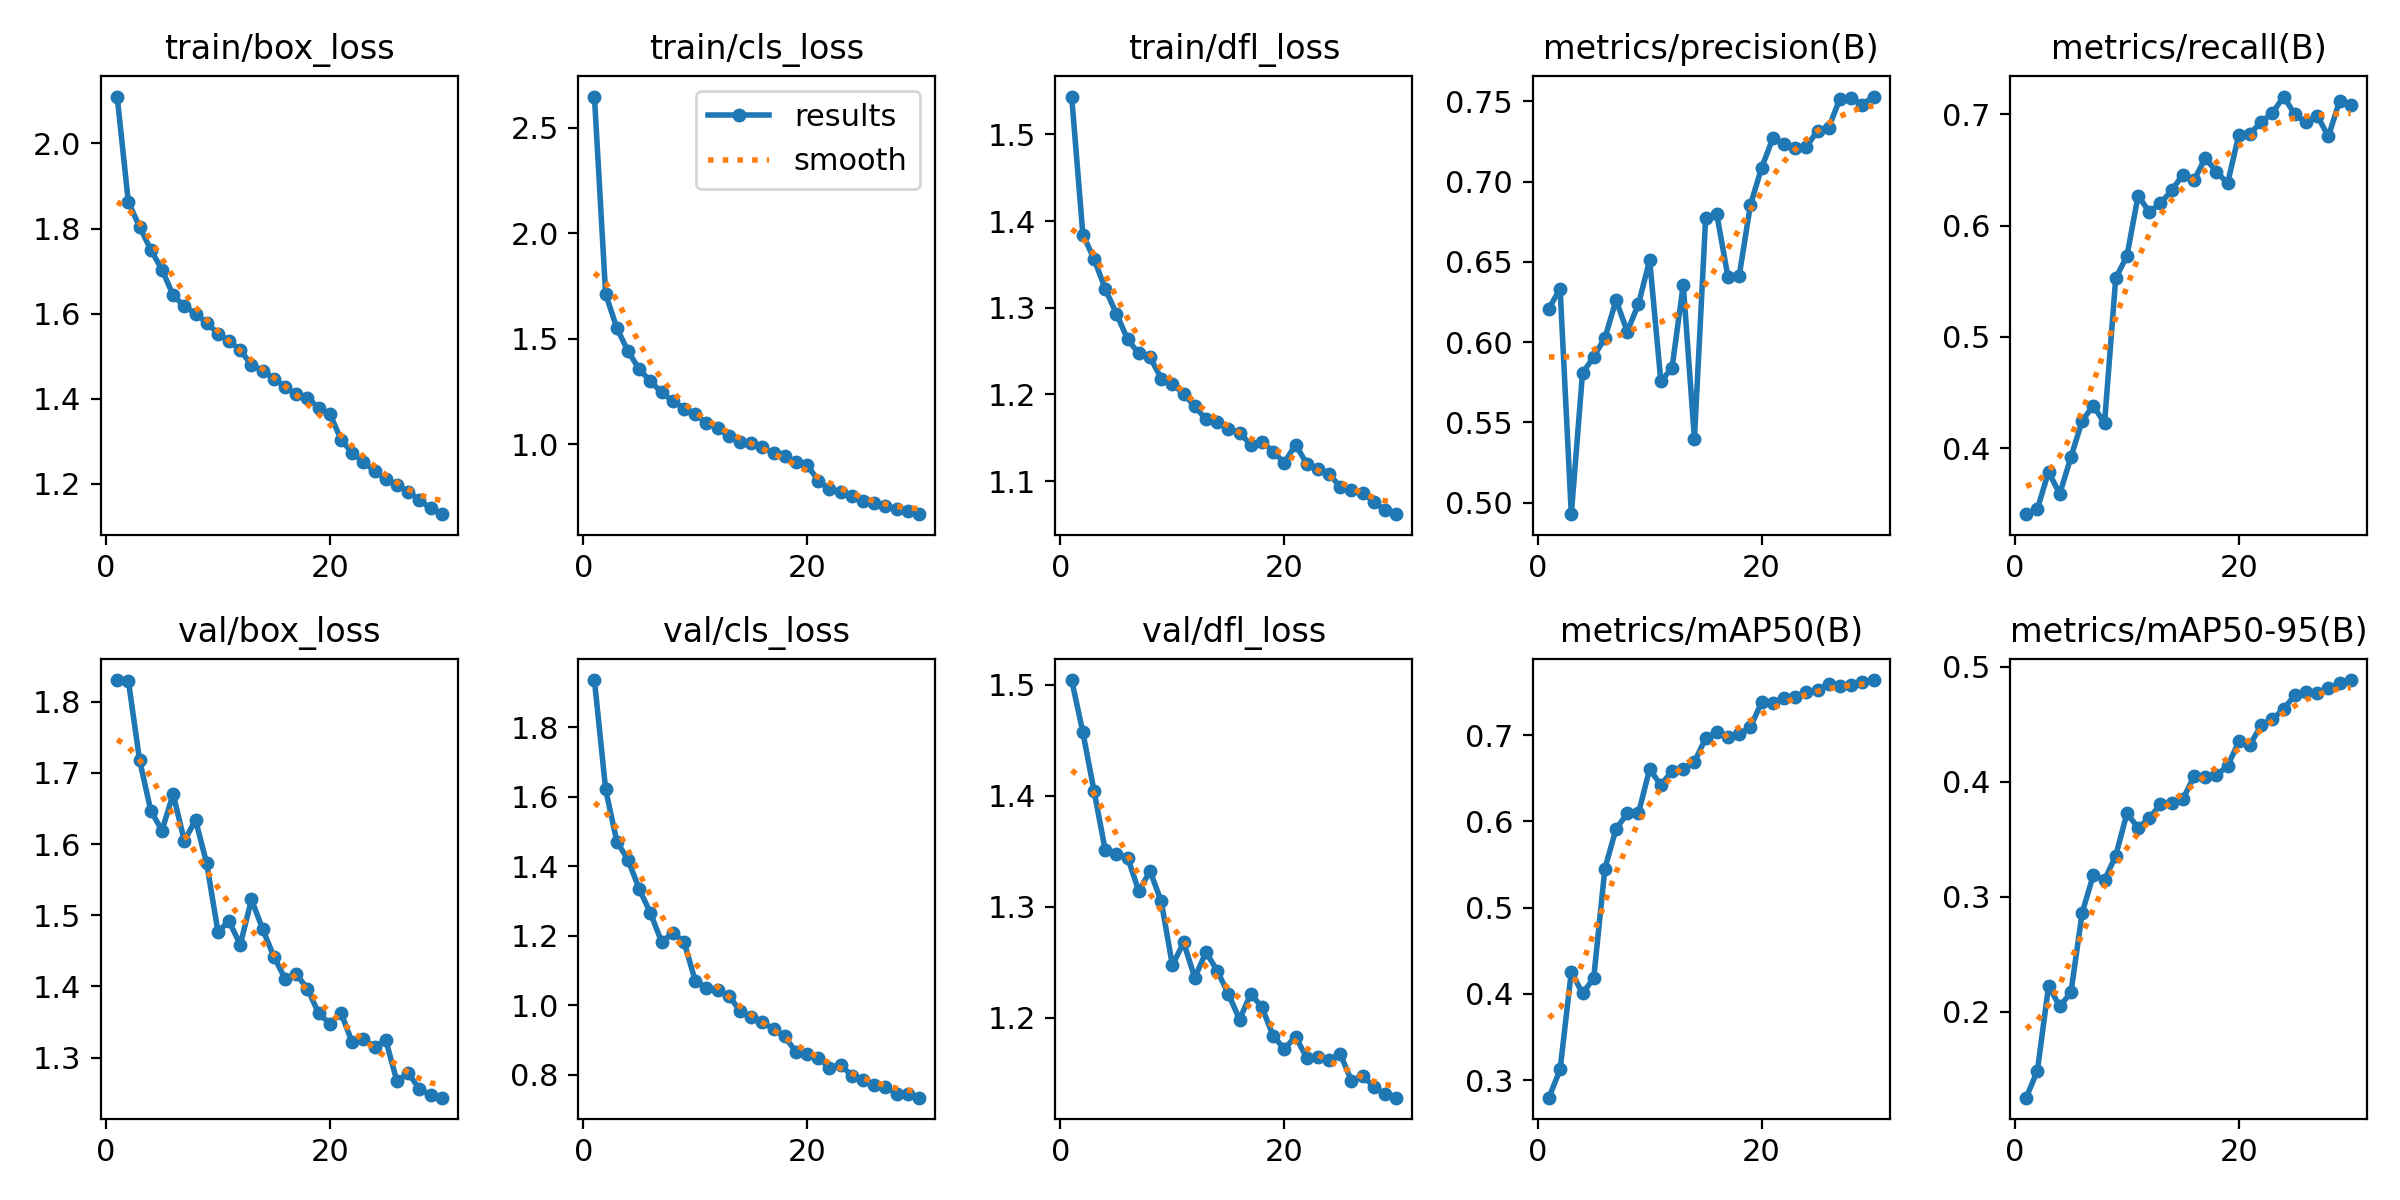

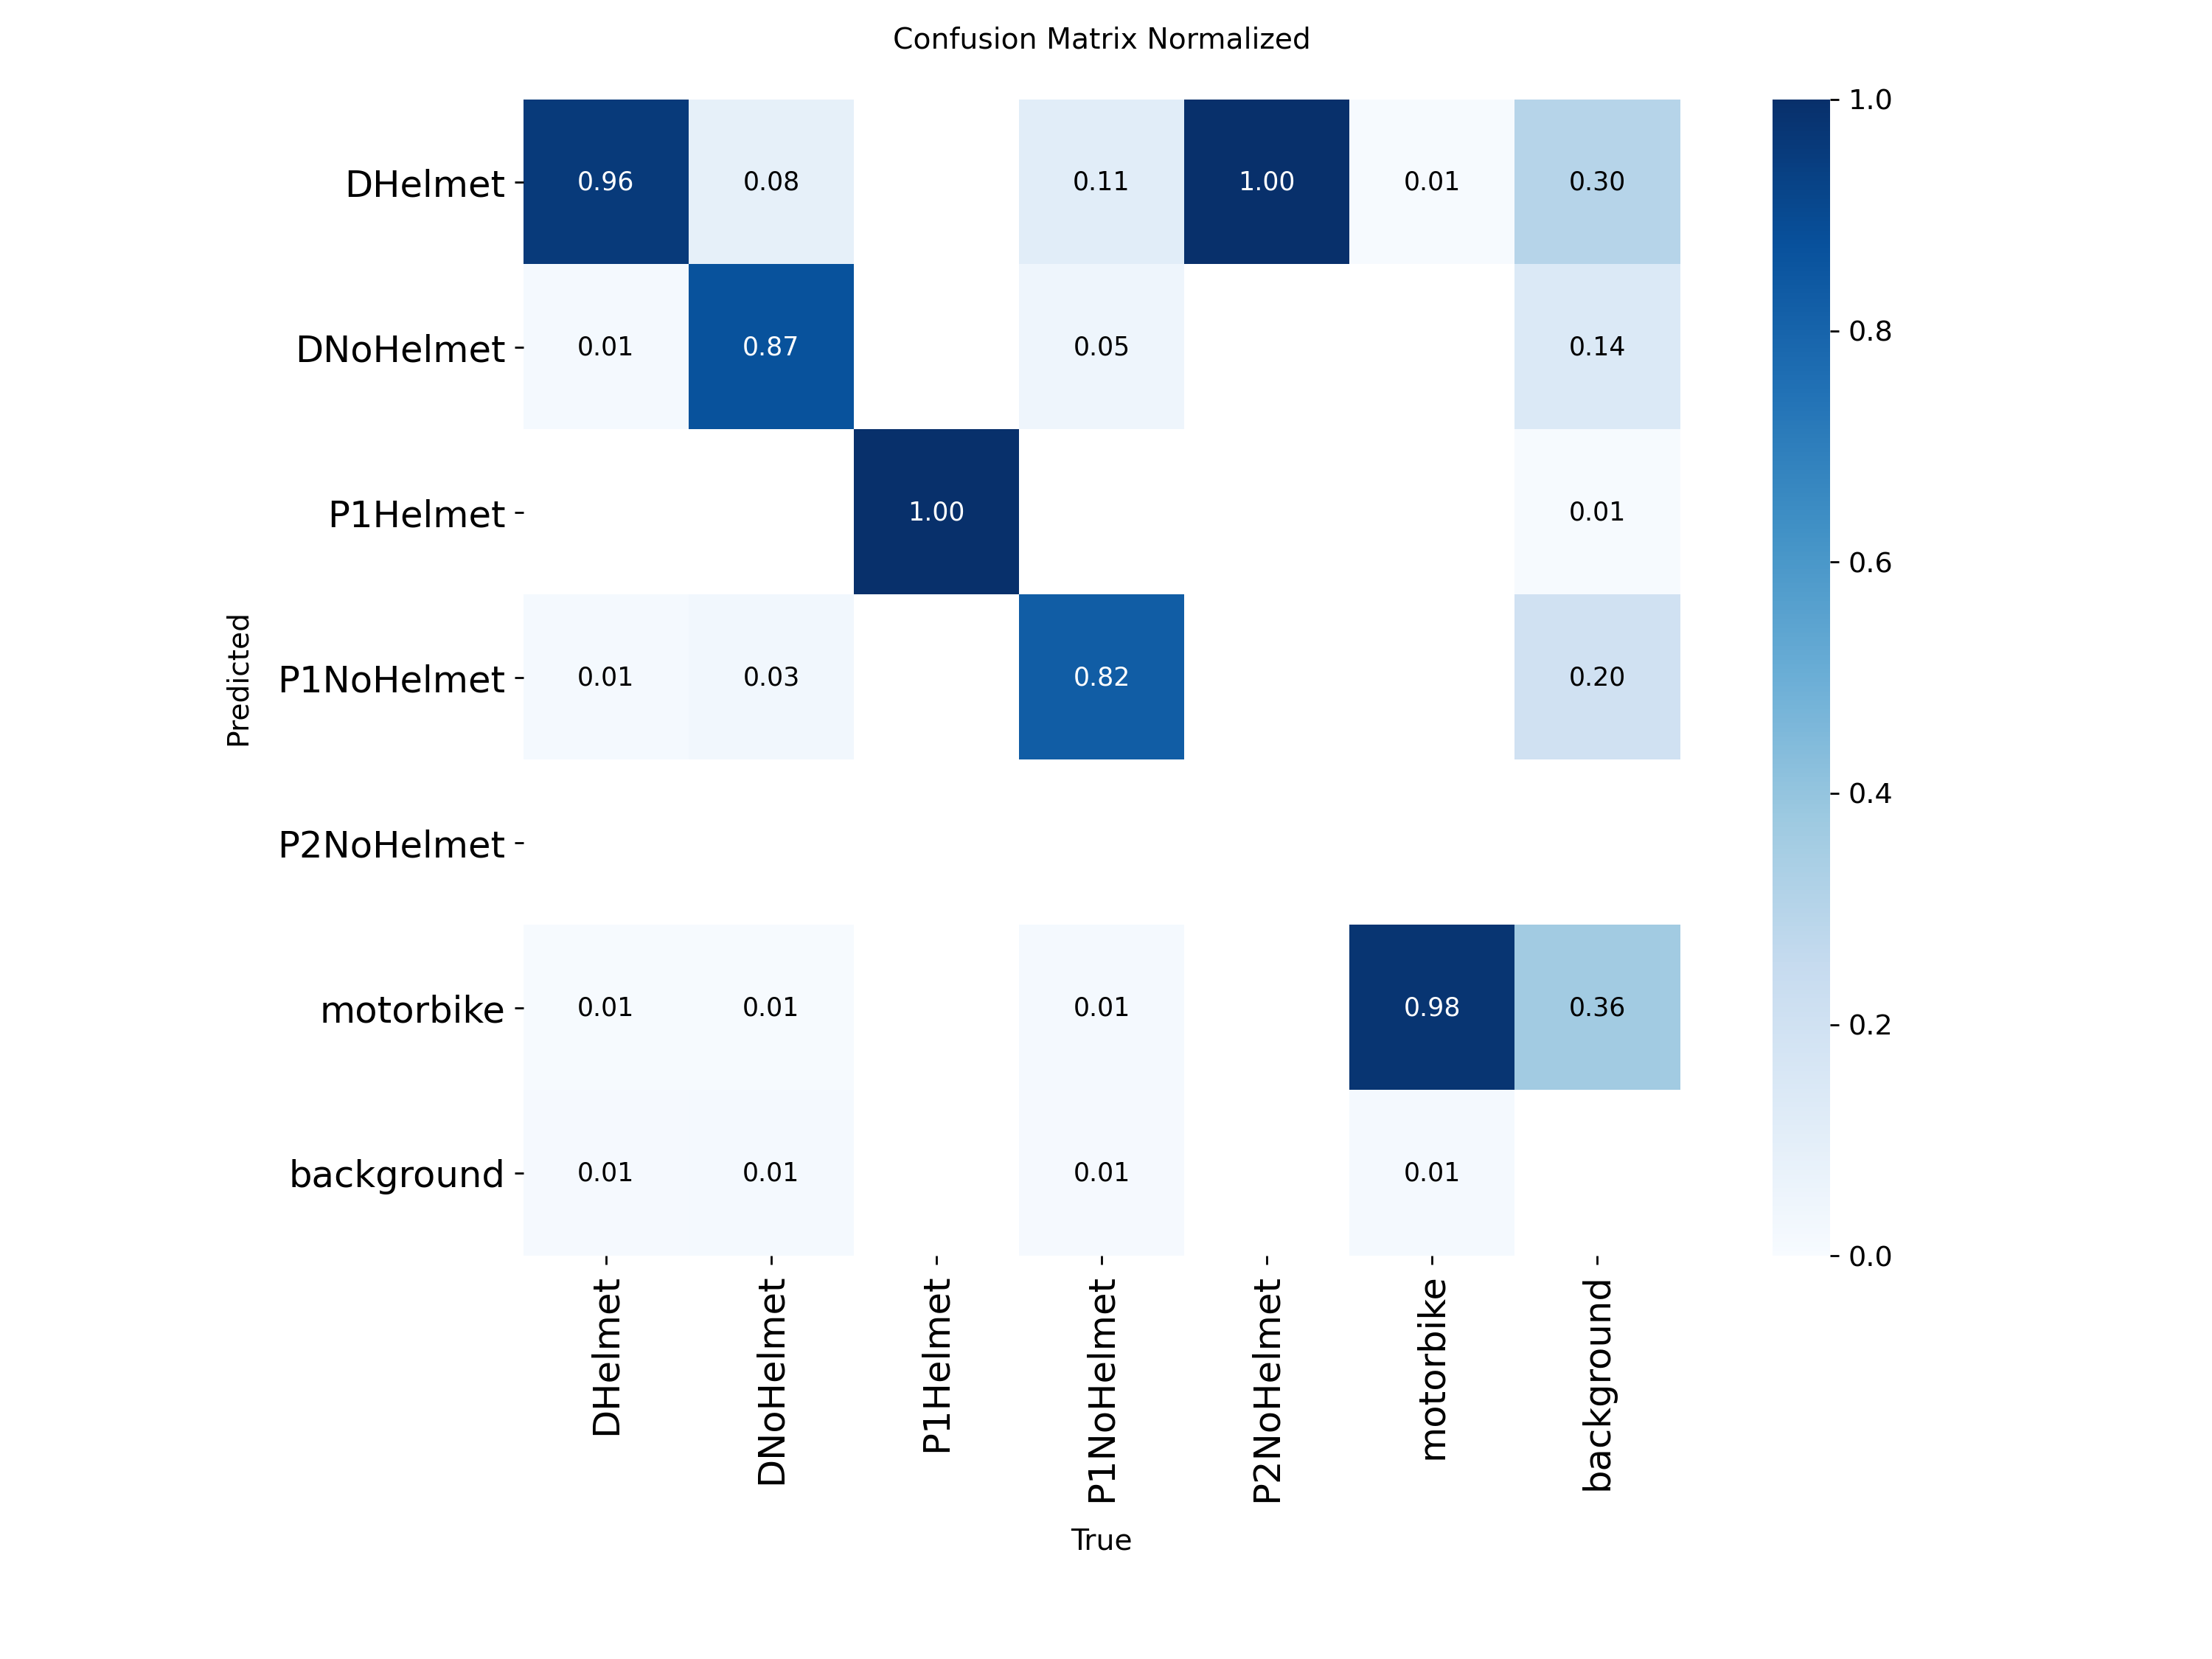

In [22]:
import pandas as pd

best_model = YOLO(BEST)
metrics = best_model.val(data=f"{root}/data.yaml", imgsz=IMGSZ, split="val")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

# Tabela de métricas por classe (a mesma impressa pelo log de validação)
p, r, ap50, ap = metrics.box.p, metrics.box.r, metrics.box.ap50, metrics.box.ap
idx = list(metrics.box.ap_class_index)
tab_classes = pd.DataFrame({
    "Classe":    [names[i] for i in idx],
    "Precisão":  p, "Recall": r, "mAP50": ap50, "mAP50-95": ap,
}).round(3).sort_values("mAP50-95")
display(tab_classes)

# Últimas épocas do log de treinamento
log = pd.read_csv(f"{RUN_DIR}/results.csv")
log.columns = [c.strip() for c in log.columns]
cols = ["epoch", "train/box_loss", "train/cls_loss", "val/box_loss",
        "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
ultimas = log[[c for c in cols if c in log.columns]].tail(5).round(4)
display(ultimas)

from IPython.display import Image as IPImage
display(IPImage(f"{RUN_DIR}/results.png", width=900))
cm = f"{RUN_DIR}/confusion_matrix_normalized.png"
display(IPImage(cm if os.path.exists(cm) else f"{RUN_DIR}/confusion_matrix.png", width=700))

### Análise (rascunho automático — revise antes de entregar)
A célula abaixo escreve um texto-base a partir das métricas. **Leia o results.png e a matriz
de confusão e ajuste** a hipótese da pior classe com o que você observou.

In [23]:
pior, melhor = tab_classes.iloc[0], tab_classes.iloc[-1]
map50, map5095 = float(metrics.box.map50), float(metrics.box.map)
nivel = "bem" if map50 >= 0.7 else ("razoavelmente" if map50 >= 0.5 else "de forma limitada")

# Contagem de instâncias por classe no treino (ajuda a explicar desempenho)
from collections import Counter
inst = Counter()
for t in glob.glob(f"{root}/train/labels/*.txt"):
    for ln in open(t).read().split("\n"):
        if ln.strip():
            inst[int(ln.split()[0])] += 1
inst_nomes = {names[k]: v for k, v in inst.items()}

conv = log["metrics/mAP50(B)"]
estabilizou = abs(conv.iloc[-1] - conv.iloc[-10:].mean()) < 0.02 if len(conv) >= 10 else False

ANALISE = (
    f"O modelo aprendeu {nivel}: no conjunto de validação obteve mAP50 = {map50:.3f} e "
    f"mAP50-95 = {map5095:.3f}. As perdas de treino e validação caem ao longo das {len(log)} épocas "
    f"e o mAP50 {'estabilizou nas últimas épocas' if estabilizou else 'ainda subia ao final, indicando que mais épocas poderiam ajudar'}. "
    f"A classe com melhor desempenho foi '{melhor['Classe']}' (mAP50-95 = {melhor['mAP50-95']:.3f}) e a pior foi "
    f"'{pior['Classe']}' (mAP50-95 = {pior['mAP50-95']:.3f}). "
    f"No treino, '{pior['Classe']}' tem {inst_nomes.get(pior['Classe'], 0)} instâncias anotadas, contra "
    f"{inst_nomes.get(melhor['Classe'], 0)} de '{melhor['Classe']}'. "
    + (f"Hipótese: a pior classe tem menos exemplos de treino, então o modelo viu menos variações dela; "
       if inst_nomes.get(pior['Classe'], 0) < inst_nomes.get(melhor['Classe'], 0) else
       f"Como a pior classe não tem menos exemplos, a hipótese é que seus objetos sejam menores, mais "
       f"variados ou parecidos com outra classe; ")
    + "na matriz de confusão isso aparece como confusão com outras classes ou com o fundo (background)."
)
print(ANALISE)
print("\nInstâncias por classe no treino:", inst_nomes)

O modelo aprendeu bem: no conjunto de validação obteve mAP50 = 0.764 e mAP50-95 = 0.489. As perdas de treino e validação caem ao longo das 30 épocas e o mAP50 estabilizou nas últimas épocas. A classe com melhor desempenho foi 'motorbike' (mAP50-95 = 0.608) e a pior foi 'P2NoHelmet' (mAP50-95 = 0.000). No treino, 'P2NoHelmet' tem 0 instâncias anotadas, contra 6975 de 'motorbike'. Hipótese: a pior classe tem menos exemplos de treino, então o modelo viu menos variações dela; na matriz de confusão isso aparece como confusão com outras classes ou com o fundo (background).

Instâncias por classe no treino: {'DNoHelmet': 1575, 'motorbike': 6975, 'DHelmet': 5019, 'P1NoHelmet': 1131, 'P1Helmet': 25}


## Passo 8 — Código de utilização (uso.py) e teste em 3+ imagens fora do treino

In [24]:
USO_PY = """\
# uso.py — exemplo simples de utilização do modelo treinado (Atividade Aula 4)
# Uso: python uso.py imagem1.jpg [imagem2.jpg ...]
import sys
from ultralytics import YOLO

model = YOLO("best.pt")                       # modelo treinado
imagens = sys.argv[1:] or ["minha_imagem.jpg"]

# conf=0.25: só mostra detecções com confiança >= 25%; save=True grava as imagens com as caixas
results = model.predict(imagens, conf=0.25, save=True)

for r in results:
    print(f"\\n{r.path}: {len(r.boxes)} objeto(s) — resultado salvo em {r.save_dir}")
    for box in r.boxes:
        print(f"  {model.names[int(box.cls)]}: {float(box.conf):.2f}")
"""
with open("/content/uso.py", "w") as f:
    f.write(USO_PY)
shutil.copy(BEST, "/content/best.pt")

# Usa imagens do conjunto de TESTE (nunca vistas no treino). Sem test, usa valid.
pasta_teste = f"{root}/test/images" if os.path.isdir(f"{root}/test/images") else f"{root}/valid/images"
testes = sorted(glob.glob(f"{pasta_teste}/*"))
random.seed(7)
testes = random.sample(testes, min(3, len(testes)))

%cd /content
!python uso.py {" ".join(testes)}

/content

0: 640x640 2 DHelmets, 1 DNoHelmet, 1 P1NoHelmet, 5 motorbikes, 7.1ms
1: 640x640 1 DHelmet, 1 P1NoHelmet, 2 motorbikes, 7.1ms
2: 640x640 2 DHelmets, 1 P1NoHelmet, 3 motorbikes, 7.1ms
Speed: 13.1ms preprocess, 7.1ms inference, 6.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict

/content/dataset/test/images/32_110_jpg.rf.657a781cd5c9257e45c755cdd4838252.jpg: 9 objeto(s) — resultado salvo em /content/runs/detect/predict
  DNoHelmet: 0.86
  motorbike: 0.80
  DHelmet: 0.79
  DHelmet: 0.74
  P1NoHelmet: 0.70
  motorbike: 0.65
  motorbike: 0.59
  motorbike: 0.54
  motorbike: 0.28

/content/dataset/test/images/9_062_jpg.rf.174bc86d82d175d69349ca42f32a1be3.jpg: 4 objeto(s) — resultado salvo em /content/runs/detect/predict
  DHelmet: 0.78
  motorbike: 0.72
  P1NoHelmet: 0.43
  motorbike: 0.43

/content/dataset/test/images/1_151_jpg.rf.57b0733cb683569b4f3736931718cc8f.jpg: 6 objeto(s) — resultado salvo em /content/runs/detect/predict
  mo

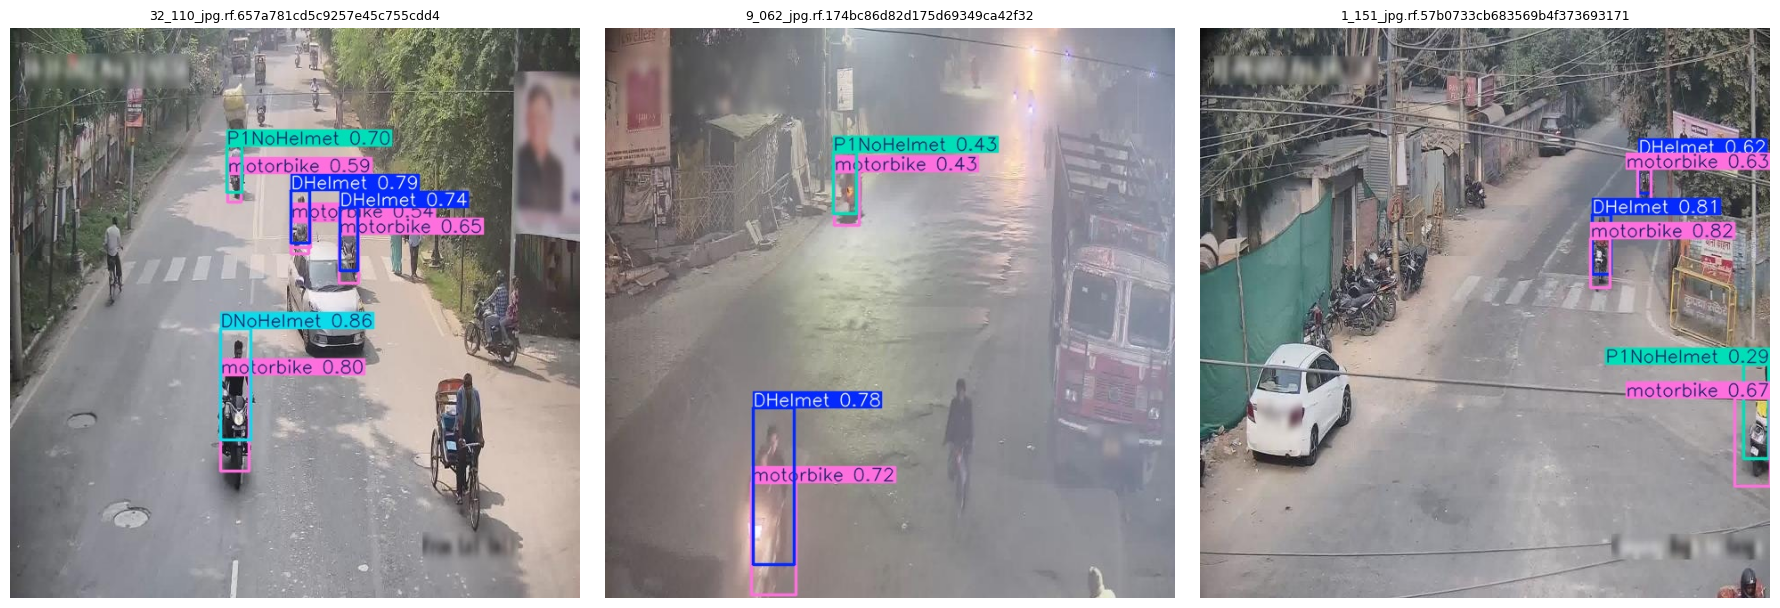

{'32_110_jpg.rf.657a781cd5c9257e45c755cdd4838252.jpg': ['DNoHelmet (0.86)',
  'motorbike (0.80)',
  'DHelmet (0.79)',
  'DHelmet (0.74)',
  'P1NoHelmet (0.70)',
  'motorbike (0.65)',
  'motorbike (0.59)',
  'motorbike (0.54)',
  'motorbike (0.28)'],
 '9_062_jpg.rf.174bc86d82d175d69349ca42f32a1be3.jpg': ['DHelmet (0.78)',
  'motorbike (0.72)',
  'P1NoHelmet (0.43)',
  'motorbike (0.43)'],
 '1_151_jpg.rf.57b0733cb683569b4f3736931718cc8f.jpg': ['motorbike (0.82)',
  'DHelmet (0.81)',
  'motorbike (0.67)',
  'motorbike (0.63)',
  'DHelmet (0.62)',
  'P1NoHelmet (0.29)']}

In [25]:
# Junta as imagens com as detecções (geradas pelo uso.py) para o relatório
pred_dirs = sorted(glob.glob("/content/runs/detect/predict*"), key=os.path.getmtime)
PRED_DIR = pred_dirs[-1]
INFERENCIAS = [os.path.join(PRED_DIR, os.path.basename(t)) for t in testes]
INFERENCIAS = [p if os.path.exists(p) else glob.glob(os.path.splitext(p)[0] + ".*")[0] for p in INFERENCIAS]

import numpy as np
fig, axes = plt.subplots(1, len(INFERENCIAS), figsize=(6 * len(INFERENCIAS), 6))
for ax, p in zip(np.atleast_1d(axes), INFERENCIAS):
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(os.path.basename(p)[:40], fontsize=9)
plt.tight_layout(); plt.show()

# Texto das detecções por imagem (vai para o relatório)
DETECCOES = {}
for r in best_model.predict(testes, conf=0.25, verbose=False):
    DETECCOES[os.path.basename(r.path)] = [f"{names[int(b.cls)]} ({float(b.conf):.2f})" for b in r.boxes]
DETECCOES

## Gerar o relatório (.docx) com todas as evidências da seção 5

In [26]:
from docx import Document
from docx.shared import Pt, Cm
from docx.enum.text import WD_ALIGN_PARAGRAPH
import datetime

doc = Document()
st = doc.styles["Normal"]; st.font.name = "Calibri"; st.font.size = Pt(10)
for s in doc.sections:
    s.top_margin = s.bottom_margin = Cm(1.6); s.left_margin = s.right_margin = Cm(1.8)

def h(t): doc.add_heading(t, level=2)
def mono(t):
    par = doc.add_paragraph(); run = par.add_run(t); run.font.name = "Consolas"; run.font.size = Pt(8)
def tabela(df):
    t = doc.add_table(rows=1, cols=len(df.columns)); t.style = "Light Grid Accent 1"
    for i, c in enumerate(df.columns):
        t.rows[0].cells[i].text = str(c).replace("metrics/", "").replace("(B)", "")
    for _, row in df.iterrows():
        cells = t.add_row().cells
        for i, v in enumerate(row): cells[i].text = str(v)
    for row in t.rows:
        for cell in row.cells:
            for p_ in cell.paragraphs:
                for r_ in p_.runs: r_.font.size = Pt(8)

titulo = doc.add_heading("Atividade Aula 4 — Detecção de objetos com YOLO", level=1)
doc.add_paragraph(f"Aluno: {ALUNO}  ·  Prof. Francisco Fambrini  ·  {datetime.date.today():%d/%m/%Y}")

h("1. Dataset")
nome_proj = DATASET_URL.rstrip("/").split("/")[-1]
doc.add_paragraph(
    f"Projeto: {nome_proj}\nLink: {DATASET_URL}\nLicença: {DATASET_LICENCA} (fonte: Roboflow Universe)\n"
    f"Imagens: {TOTAL_IMAGENS} (train {contagem['train'][0]}, valid {contagem['valid'][0]}, test {contagem['test'][0]})"
    f"  ·  Classes ({len(names)}): {', '.join(names)}\n"
    f"Modelo base: {MODELO_BASE}  ·  Épocas: {EPOCAS}  ·  imgsz: {IMGSZ}  ·  batch: {BATCH}  ·  GPU: Colab T4")

h("2. data.yaml (após ajuste para caminhos absolutos)")
mono(DATA_YAML_TXT)

h("3. Estrutura das pastas e contagem de arquivos (saída do Passo 4)")
mono("\n".join(f"{s}/images: {c[0]:>5} arquivos   |   {s}/labels: {c[1]:>5} arquivos"
               for s, c in contagem.items()))

h("4. Exemplos do treino com as anotações")
doc.add_picture(f"{EVID}/amostras_treino.png", width=Cm(10.5))
doc.add_paragraph(f"Label {os.path.basename(LABEL_EXEMPLO_PATH)} (classe x_centro y_centro largura altura, normalizados 0–1):")
mono("\n".join(LABEL_EXEMPLO[:6]))

h("5. Log do treinamento — últimas épocas")
tabela(ultimas)
doc.add_paragraph()
doc.add_paragraph("Métricas por classe (validação, best.pt):")
linha_all = pd.DataFrame([{"Classe": "all", "Precisão": round(float(metrics.box.mp), 3),
                           "Recall": round(float(metrics.box.mr), 3),
                           "mAP50": round(map50, 3), "mAP50-95": round(map5095, 3)}])
tabela(pd.concat([linha_all, tab_classes]))

h("6. Gráficos gerados")
doc.add_picture(f"{RUN_DIR}/results.png", width=Cm(16))
doc.add_picture(cm if os.path.exists(cm) else f"{RUN_DIR}/confusion_matrix.png", width=Cm(11))

h("7. Resultados de inferência (imagens fora do treino, conf ≥ 0,25)")
tinf = doc.add_table(rows=1, cols=len(INFERENCIAS))   # imagens lado a lado
for cell, p in zip(tinf.rows[0].cells, INFERENCIAS):
    cell.paragraphs[0].add_run().add_picture(p, width=Cm(5.4))
    det = DETECCOES.get(os.path.basename(p), [])
    cap = cell.add_paragraph(f"{os.path.basename(p)[:30]}: " + (", ".join(det) if det else "nenhuma detecção"))
    for r_ in cap.runs: r_.font.size = Pt(8)

h("8. Análise dos resultados")
doc.add_paragraph(ANALISE)

RELATORIO = f"/content/Relatorio_{NOME_ZIP}.docx"
doc.save(RELATORIO)
print("Relatório salvo em", RELATORIO)

Relatório salvo em /content/Relatorio_AULA4_WalterGuilhermino.docx


## Passo 9 — Montar e baixar o .zip de entrega

In [ ]:
# Salva uma cópia deste notebook como treino.ipynb (sem a chave do Roboflow, que nunca foi gravada)
from google.colab import _message, files
import json as _json
nb = _message.blocking_request("get_ipynb", timeout_sec=30)["ipynb"]
with open("/content/treino.ipynb", "w") as f:
    _json.dump(nb, f)

ZIP = f"/content/{NOME_ZIP}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write("/content/treino.ipynb", "treino.ipynb")
    z.write("/content/uso.py", "uso.py")
    z.write("/content/best.pt", "best.pt")
    z.write(RELATORIO, os.path.basename(RELATORIO))
print("Conteúdo do zip:", zipfile.ZipFile(ZIP).namelist())

if SALVAR_NO_DRIVE:
    shutil.copy(ZIP, "/content/drive/MyDrive/")
files.download(ZIP)